# REINFORCE

优化目标：最大化采样得到的轨迹的期望。根据 Monte-Carlo，收集完整的轨迹，计算策略梯度更新策略。

$p_\theta(s_1, a_1, ..., s_T,a_T)=p(s_1)\prod_{t=1}^T \pi_\theta(a_t|s_t)p(s_{t+1},a_t)\\$
$\theta^*=\arg\max_\theta J(\theta)=\arg\max_\theta E_{\tau\sim p_\theta(\tau)}[\sum_t r(s_t,a_t)]\\$
根据优化目标，就是对采样的轨迹的期望回报求梯度，用于更新策略

$J(\theta)=E_{\tau\sim p_\theta(\tau)}[r(\tau)]=\int p_\theta(\tau)r(\tau)d\tau\\$
$\nabla J(\theta)=\int \nabla_\theta p_\theta(\tau)r(\tau)d\tau\\$
单纯根据这个公式是没法更新策略$\pi_\theta$的

根据<img src="./assets/策略梯度.png" alt="策略梯度" width="250"/>
$\\ \nabla J(\theta)=\int \nabla_\theta p_\theta(\tau)r(\tau)d\tau
=\int p_\theta(\tau)\nabla_\theta \log p_\theta(\tau)r(\tau)d\tau
=E_{\tau\sim p_\theta(\tau)}[\nabla_\theta \log p_\theta(\tau)r(\tau)]\\$
其中，$\log p_\theta(\tau)=\log p(s_1)+\sum^T_{t=1}\log \pi_\theta(a_t|s_t)+\log p(s_{t+1}|s_t,a_t)\\$
一、三两项与$\theta$无关，所以$\nabla_\theta \log p_\theta(\tau)=\sum^T_{t=1}\nabla_\theta \log \pi_\theta(a_t|s_t)\\$
所以$\nabla_\theta J(\theta)=E_{\tau\sim p_\theta(\tau)}[(\sum^T_{t=1}\nabla_\theta \log\pi_\theta(a_t|s_t))(\sum^T_{t=1}r(s_t,a_t))]$


<img src="./assets/REINFORCE.png" alt="REINFORCE" width="400"/>

import modules

In [1]:
import gym
import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import rl_utils

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


这里策略网络的输出是一个可学习的分布

In [2]:
class PolicyNet(torch.nn.Module):
    def __init__(self, state_dim, hidden_dim, action_dim):
        super(PolicyNet, self).__init__()
        self.fc1 = torch.nn.Linear(state_dim, hidden_dim)
        self.fc2 = torch.nn.Linear(hidden_dim, action_dim)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        return F.softmax(self.fc2(x), dim=1)

In [3]:
class REINFORCE:
    def __init__(self, state_dim, hidden_dim, action_dim, learning_rate, gamma, device):
        self.policy_net = PolicyNet(state_dim, hidden_dim, action_dim)
        self.optimizer = torch.optim.Adam(self.policy_net.parameters(), lr=learning_rate)
        self.gamma = gamma
        self.device = device
    
    def take_action(self, state):
        state = torch.tensor([state], dtype=torch.float).to(self.device)
        probs = self.policy_net(state)
        # 这里训练的时候是需要在分布中采样的
        action_dist = torch.distributions.Categorical(probs)
        action = action_dist.sample()
        return action.item()
    
    def update(self, transition_dict):
        reward_list = transition_dict['rewards']
        state_list = transition_dict['states']
        action_list = transition_dict['actions']

        Return = 0
        self.optimizer.zero_grad()
        # 这次从后往前可以方便计算折扣回报
        for i in reversed(range(len(reward_list))):
            reward = reward_list[i]
            state = torch.tensor([state_list[i]],
                                 dtype=torch.float).to(self.device)
            action = torch.tensor([action_list[i]]).view(-1, 1).to(self.device)
            # 计算log{pi(at|st)}
            log_prob = torch.log(self.policy_net(state).gather(1, action))
            Return = self.gamma * Return + reward
            loss = -log_prob * Return
            loss.backward()
        self.optimizer.step()

In [4]:
learning_rate = 1e-3
num_episodes = 1000
hidden_dim = 128
gamma = 0.98
device = torch.device("cuda") if torch.cuda.is_available() else torch.device(
    "cpu")

env_name = "CartPole-v0"
env = gym.make(env_name)
env.seed(0)
torch.manual_seed(0)
state_dim = env.observation_space.shape[0]
action_dim = env.action_space.n
agent = REINFORCE(state_dim, hidden_dim, action_dim, learning_rate, gamma,
                  device)

return_list = []
for i in range(10):
    with tqdm(total=int(num_episodes / 10), desc='Iteration %d' % i) as pbar:
        for i_episode in range(int(num_episodes / 10)):
            episode_return = 0
            transition_dict = {
                'states': [],
                'actions': [],
                'next_states': [],
                'rewards': [],
                'dones': []
            }
            state = env.reset()
            done = False
            while not done:
                action = agent.take_action(state)
                next_state, reward, done, _ = env.step(action)
                transition_dict['states'].append(state)
                transition_dict['actions'].append(action)
                transition_dict['next_states'].append(next_state)
                transition_dict['rewards'].append(reward)
                transition_dict['dones'].append(done)
                state = next_state
                episode_return += reward
            return_list.append(episode_return)
            agent.update(transition_dict)
            if (i_episode + 1) % 10 == 0:
                pbar.set_postfix({
                    'episode':
                    '%d' % (num_episodes / 10 * i + i_episode + 1),
                    'return':
                    '%.3f' % np.mean(return_list[-10:])
                })
            pbar.update(1)

/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/envs/registration.py:592: UserWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.warn(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:329: DeprecationWarning: WARN: Initializing wrapper in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/wrappers/step_api_compatibility.py:39: DeprecationWarning: WARN: Initializing environment in old step API which returns one bool instead of two. It is recommended to set `new_step_api=True` to use new step API. This will be the default behaviour in future.
  deprecation(
/opt/miniconda3/envs/CRL/lib/python3.10/site-packages/gym/core.py:268: DeprecationWarning: WARN: Function `env.seed(seed)` is marked as deprecated and will be re

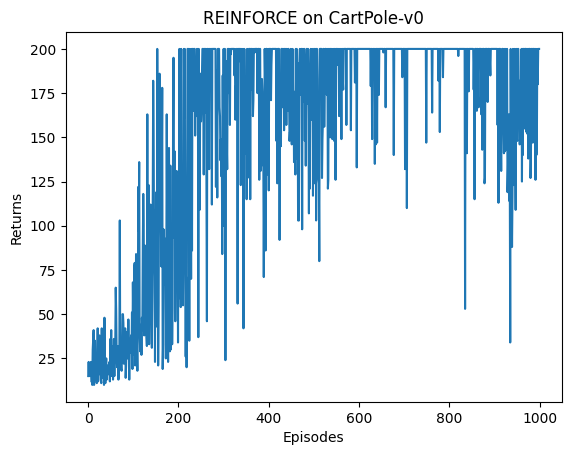

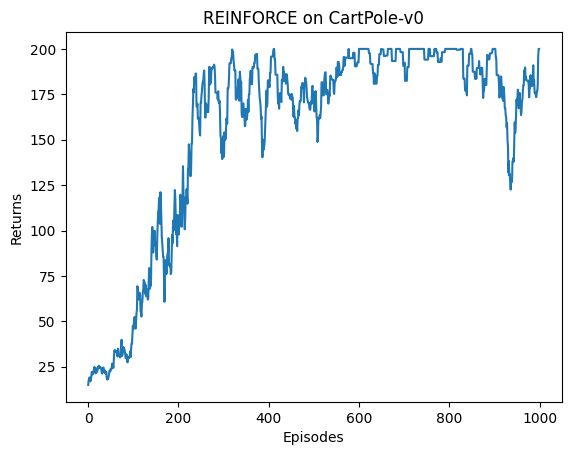

In [5]:
episodes_list = list(range(len(return_list)))
plt.plot(episodes_list, return_list)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('REINFORCE on {}'.format(env_name))
plt.show()

mv_return = rl_utils.moving_average(return_list, 9)
plt.plot(episodes_list, mv_return)
plt.xlabel('Episodes')
plt.ylabel('Returns')
plt.title('REINFORCE on {}'.format(env_name))
plt.show()

这个方法的问题就在于他对于状态价值的估计是基于Monte-Carlo采样得到的，数据方差非常大，训练不稳定